# 2. QUBO formulation, brute force and simulated annealing

Owner: B

Steps in this notebook:
1. Load the 10 "mean" features of the Breast Cancer dataset
2. Score each feature (relevance) and each pair of features (redundancy)
3. Build a QUBO that picks exactly k features
4. Solve it exactly by brute force (tries every subset)
5. Solve it with simulated annealing (a classical heuristic)
6. Convert the QUBO to Ising form for the QAOA notebook
7. Save the chosen feature indices, e.g. `[0, 3, 7]`, to `results/`

In [37]:
import itertools
import json
import os
import time

import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer

## 1. Load the 10 mean features

In [38]:
data = load_breast_cancer()
X_all = data.data[:, :10]  # the first 10 columns are the 'mean' features
y = data.target            # 0 = malignant, 1 = benign
feature_names = [str(name) for name in data.feature_names[:10]]

print(X_all.shape)
for i, name in enumerate(feature_names):
    print(i, name)

(569, 10)
0 mean radius
1 mean texture
2 mean perimeter
3 mean area
4 mean smoothness
5 mean compactness
6 mean concavity
7 mean concave points
8 mean symmetry
9 mean fractal dimension


## 2. Relevance and redundancy

- **Relevance** of feature i: $r_i = |\text{corr}(\text{feature}_i, \text{target})|$. Between 0 and 1; higher = more useful for predicting the diagnosis.
- **Redundancy** of features i and j: $R_{ij} = |\text{corr}(\text{feature}_i, \text{feature}_j)|$. Between 0 and 1; higher = they carry the same information.

Note: the scores use the whole dataset. Strictly, they should use only the training split, otherwise a little test information leaks into the selection. Worth mentioning in the report.

In [39]:
def relevance_scores(X, y):
    return np.array([abs(np.corrcoef(X[:, i], y)[0, 1]) for i in range(X.shape[1])])


def redundancy_matrix(X):
    R = np.abs(np.corrcoef(X, rowvar=False))
    np.fill_diagonal(R, 0.0)  # a feature is not 'redundant with itself'
    return R


r = relevance_scores(X_all, y)
R = redundancy_matrix(X_all)

print('Relevance (sorted, higher = more useful):')
for i in np.argsort(-r):
    print(f'  {i:2d}  {feature_names[i]:<25s} {r[i]:.3f}')

Relevance (sorted, higher = more useful):
   7  mean concave points       0.777
   2  mean perimeter            0.743
   0  mean radius               0.730
   3  mean area                 0.709
   6  mean concavity            0.696
   5  mean compactness          0.597
   1  mean texture              0.415
   4  mean smoothness           0.359
   8  mean symmetry             0.330
   9  mean fractal dimension    0.013


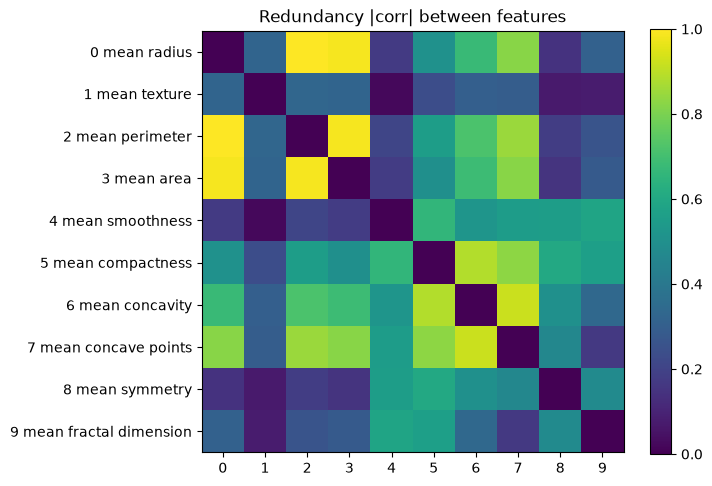

In [40]:
fig, ax = plt.subplots(figsize=(7, 5))
im = ax.imshow(R, cmap='viridis', vmin=0, vmax=1)
ax.set_xticks(range(10))
ax.set_yticks(range(10))
ax.set_yticklabels([f'{i} {name}' for i, name in enumerate(feature_names)])
ax.set_title('Redundancy |corr| between features')
fig.colorbar(im)
plt.tight_layout()
plt.show()

## 3. The QUBO

Each feature gets a bit: $x_i = 1$ means "feature i is chosen". We want the bitstring with the **lowest** energy:

$$E(x) = -\alpha \sum_i r_i x_i \; + \; (1-\alpha) \sum_{i<j} R_{ij} x_i x_j \; + \; \lambda \Big(\sum_i x_i - k\Big)^2$$

- 1st term: choosing relevant features lowers the energy (reward).
- 2nd term: choosing two similar features raises the energy (penalty).
- 3rd term: zero when exactly k features are chosen, positive otherwise.
- $\alpha$ (0 to 1) trades off relevance vs redundancy.

**Turning it into a matrix.** Because $x_i^2 = x_i$ for bits, the penalty expands to
$\lambda(1-2k)\sum_i x_i + 2\lambda\sum_{i<j} x_i x_j + \lambda k^2$.
So everything fits in an upper-triangular matrix $Q$ plus a constant $c$:

$$E(x) = x^T Q x + c, \quad Q_{ii} = -\alpha r_i + \lambda(1-2k), \quad Q_{ij} = (1-\alpha)R_{ij} + 2\lambda \ (i<j), \quad c = \lambda k^2$$

**Choosing $\lambda$.** Adding one feature can lower the first two terms by at most $\alpha \max_i r_i$; removing one can lower them by at most $(1-\alpha)\max_i \sum_j R_{ij}$. If $\lambda$ is bigger than both, the best subset always has exactly k features. Too large a $\lambda$ is also bad for QAOA (the penalty drowns out the real objective), so we pick just above this bound.

In [41]:
def build_qubo(r, R, k, alpha=0.5, lam=None):
    # Returns (Q, const, lam) with energy(x) = x @ Q @ x + const.
    # Q is upper triangular. Lower energy = better feature subset.
    n = len(r)
    if lam is None:
        lam = max(alpha * r.max(), (1 - alpha) * R.sum(axis=1).max()) + 0.1
    Q = np.zeros((n, n))
    for i in range(n):
        Q[i, i] = -alpha * r[i] + lam * (1 - 2 * k)
        for j in range(i + 1, n):
            Q[i, j] = (1 - alpha) * R[i, j] + 2 * lam
    const = lam * k ** 2
    return Q, const, lam


def qubo_energy(x, Q, const):
    x = np.asarray(x)
    return float(x @ Q @ x + const)


def bits_to_indices(x):
    # [0, 1, 0, 1, ...] -> [1, 3, ...]  (the shared output format)
    return [int(i) for i in np.flatnonzero(x)]


def indices_to_bits(indices, n):
    x = np.zeros(n, dtype=int)
    x[list(indices)] = 1
    return x

In [42]:
K = 3        # feature budget
ALPHA = 0.5  # relevance vs redundancy weight

Q, const, lam = build_qubo(r, R, K, ALPHA)
n = len(r)
print(f'lambda = {lam:.3f}')

# Sanity check: the matrix form gives the same energy as the formula written out
rng = np.random.default_rng(0)
for _ in range(20):
    x = rng.integers(0, 2, n)
    pair_sum = sum(R[i, j] * x[i] * x[j] for i in range(n) for j in range(i + 1, n))
    direct = -ALPHA * (r @ x) + (1 - ALPHA) * pair_sum + lam * (x.sum() - K) ** 2
    assert np.isclose(direct, qubo_energy(x, Q, const))
print('QUBO matrix matches the formula')

lambda = 2.963
QUBO matrix matches the formula


## 4. Brute force (exact optimum)

With 10 features there are only $2^{10} = 1024$ bitstrings, so we can simply try them all. This gives the true best answer, which we use to check QAOA and simulated annealing.

(This stops being practical quickly: 30 features = about a billion bitstrings.)

In [43]:
def brute_force(Q, const):
    # Try every bitstring. Returns a list of (energy, bits), best first.
    n = Q.shape[0]
    results = [(qubo_energy(bits, Q, const), bits) for bits in itertools.product([0, 1], repeat=n)]
    results.sort(key=lambda t: t[0])
    return results


t0 = time.perf_counter()
all_results = brute_force(Q, const)
bf_time = time.perf_counter() - t0

best_E, best_bits = all_results[0]
selected_bf = bits_to_indices(best_bits)
assert len(selected_bf) == K, 'lambda too small: best subset does not have k features'

print(f'Brute force ({bf_time:.3f} s): {selected_bf}  energy = {best_E:.4f}')
print('Top 5 subsets:')
for E, bits in all_results[:5]:
    idx = bits_to_indices(bits)
    print(f'  {E:8.4f}  {idx}  {[feature_names[i] for i in idx]}')

Brute force (0.003 s): [0, 1, 4]  energy = -0.4930
Top 5 subsets:
   -0.4930  [0, 1, 4]  ['mean radius', 'mean texture', 'mean smoothness']
   -0.4806  [1, 3, 4]  ['mean texture', 'mean area', 'mean smoothness']
   -0.4781  [1, 2, 4]  ['mean texture', 'mean perimeter', 'mean smoothness']
   -0.4664  [0, 1, 8]  ['mean radius', 'mean texture', 'mean symmetry']
   -0.4554  [1, 3, 8]  ['mean texture', 'mean area', 'mean symmetry']


## 5. Simulated annealing (classical heuristic)

Idea, like slowly cooling metal:
1. Start from a random bitstring.
2. Flip one random bit.
3. If the energy goes down, keep the flip. If it goes up by $\Delta E$, keep it anyway with probability $e^{-\Delta E / T}$.
4. Slowly lower the "temperature" $T$, so bad moves become rarer. Repeat.

Early on (high T) it explores; at the end (low T) it settles into a good answer. It is not guaranteed to find the optimum, so we restart it a few times and keep the best.

In [44]:
def simulated_annealing(Q, const, n_steps=2000, T_start=5.0, T_end=0.01, n_restarts=5, seed=None):
    rng = np.random.default_rng(seed)
    n = Q.shape[0]
    best_x, best_E = None, np.inf
    for _ in range(n_restarts):
        x = rng.integers(0, 2, n)
        E = qubo_energy(x, Q, const)
        for step in range(n_steps):
            T = T_start * (T_end / T_start) ** (step / (n_steps - 1))  # cools from T_start to T_end
            i = rng.integers(n)
            x_new = x.copy()
            x_new[i] = 1 - x_new[i]
            E_new = qubo_energy(x_new, Q, const)
            if E_new < E or rng.random() < np.exp(-(E_new - E) / T):
                x, E = x_new, E_new
            if E < best_E:
                best_x, best_E = x.copy(), E
    return best_x, best_E


t0 = time.perf_counter()
x_sa, E_sa = simulated_annealing(Q, const, seed=0)
sa_time = time.perf_counter() - t0
selected_sa = bits_to_indices(x_sa)
print(f'Simulated annealing ({sa_time:.3f} s): {selected_sa}  energy = {E_sa:.4f}')
print('Same as brute force?', np.isclose(E_sa, best_E))

Simulated annealing (0.056 s): [0, 1, 4]  energy = -0.4930
Same as brute force? True


In [45]:
# How reliable is SA? Run it with 20 different seeds (same metric we use for QAOA).
n_runs = 20
hits = 0
for s in range(n_runs):
    _, E_s = simulated_annealing(Q, const, seed=s)
    hits += int(np.isclose(E_s, best_E))
print(f'SA found the exact optimum in {hits}/{n_runs} runs')

SA found the exact optimum in 18/20 runs


## 6. Ising form (for the QAOA notebook)

Qubits naturally use spins $z_i \in \{+1, -1\}$ instead of bits. Substitute $x_i = (1 - z_i)/2$:

$$E = \sum_i h_i z_i + \sum_{i<j} J_{ij} z_i z_j + \text{offset}$$

Convention: $x_i = 0 \leftrightarrow z_i = +1 \leftrightarrow$ qubit $|0\rangle$, and $x_i = 1 \leftrightarrow z_i = -1 \leftrightarrow$ qubit $|1\rangle$.

Warning for QAOA: Qiskit prints bitstrings with qubit 0 on the **right**, so reverse the string before calling `bits_to_indices`.

In [46]:
def qubo_to_ising(Q, const):
    # Returns h, J, offset with energy = h @ z + z @ J @ z + offset  (J upper triangular)
    n = Q.shape[0]
    h = np.zeros(n)
    J = np.zeros((n, n))
    offset = const
    for i in range(n):
        h[i] -= Q[i, i] / 2
        offset += Q[i, i] / 2
        for j in range(i + 1, n):
            J[i, j] = Q[i, j] / 4
            h[i] -= Q[i, j] / 4
            h[j] -= Q[i, j] / 4
            offset += Q[i, j] / 4
    return h, J, offset


h, J, offset = qubo_to_ising(Q, const)
for E, bits in all_results:
    z = 1 - 2 * np.array(bits)
    assert np.isclose(E, h @ z + z @ J @ z + offset)
print('Ising form matches the QUBO for all 1024 bitstrings')

Ising form matches the QUBO for all 1024 bitstrings


## 7. Results for k = 2..5, saved for the team

Saved to `results/qubo_selections.json`. For each k (keys are strings: `'2'`, `'3'`, ...):
- `bruteforce`, `simulated_annealing`: chosen feature indices (shared format)
- `Q`, `const`, `lambda`: the QUBO, so QAOA solves exactly the same problem
- `energy_min`, `energy_max`: for the QAOA approximation ratio $(E_{max} - E)/(E_{max} - E_{min})$

Smaller problems (6 or 8 features): pick indices `idx` and call `build_qubo(r[idx], R[np.ix_(idx, idx)], k)`.

In [47]:
RESULTS_DIR = os.path.join('..', 'results')
os.makedirs(RESULTS_DIR, exist_ok=True)

summary = {
    'alpha': ALPHA,
    'feature_names': feature_names,
    'relevance': r.tolist(),
    'redundancy': R.tolist(),
    'by_k': {},
}

for k in [2, 3, 4, 5]:
    Q_k, c_k, lam_k = build_qubo(r, R, k, ALPHA)
    res = brute_force(Q_k, c_k)
    x_k, E_k = simulated_annealing(Q_k, c_k, seed=0)
    bf = bits_to_indices(res[0][1])
    sa = bits_to_indices(x_k)
    summary['by_k'][str(k)] = {
        'lambda': lam_k,
        'Q': Q_k.tolist(),
        'const': c_k,
        'energy_min': res[0][0],
        'energy_max': res[-1][0],
        'bruteforce': bf,
        'simulated_annealing': sa,
    }
    status = 'same' if np.isclose(E_k, res[0][0]) else 'SA missed the optimum'
    print(f'k={k}: brute force {bf}   SA {sa}   ({status})')

out_path = os.path.join(RESULTS_DIR, 'qubo_selections.json')
with open(out_path, 'w') as f:
    json.dump(summary, f, indent=2)
print('Saved to', out_path)

k=2: brute force [0, 4]   SA [0, 4]   (same)
k=3: brute force [0, 1, 4]   SA [0, 1, 4]   (same)
k=4: brute force [0, 1, 4, 8]   SA [0, 1, 4, 8]   (same)
k=5: brute force [0, 1, 3, 4, 8]   SA [0, 1, 3, 4, 8]   (same)
Saved to ..\results\qubo_selections.json


In [48]:
# Final answer for the main setting (k = 3), in the shared format
print('Brute force:        ', selected_bf, [feature_names[i] for i in selected_bf])
print('Simulated annealing:', selected_sa, [feature_names[i] for i in selected_sa])

Brute force:         [0, 1, 4] ['mean radius', 'mean texture', 'mean smoothness']
Simulated annealing: [0, 1, 4] ['mean radius', 'mean texture', 'mean smoothness']
